# CurrentSense MLOps — Motor/Fan Sound Classification
**New MLOps Summative | Binary normal vs abnormal classification from real WAV audio.**

**Continuity:** The earlier CurrentSense summative used 48 numerical descriptors extracted from electric-motor currents (11 classes). This project extends the *machine condition-monitoring use case* to non-tabular acoustic recordings. The previous test accuracy does **not** transfer to this new model. Data: [MIMII original dataset](https://doi.org/10.5281/zenodo.3384388), CC BY-SA 4.0.



In [3]:
from pathlib import Path
from collections import Counter

# Works when the notebook is opened from the project root
project = Path.cwd()
if not (project / "data").exists():
    project = project.parent

data_root = project / "data"

for split in ["train", "val", "test"]:
    files = list((data_root / split).rglob("*.wav"))
    labels = Counter(p.parent.name for p in files)

    print(f"{split}: {len(files)} recordings")
    print(f"  Labels: {dict(labels)}")

print("\nExample genuine MIMII recordings:")

for split in ["train", "val", "test"]:
    files = sorted((data_root / split).rglob("*.wav"))

    print(f"\n{split.upper()} examples:")

    for p in files[:3]:
        print(p.relative_to(project))

train: 420 recordings
  Labels: {'abnormal': 210, 'normal': 210}
val: 90 recordings
  Labels: {'abnormal': 45, 'normal': 45}
test: 90 recordings
  Labels: {'abnormal': 45, 'normal': 45}

Example genuine MIMII recordings:

TRAIN examples:
data\train\abnormal\id_00_00000001.wav
data\train\abnormal\id_00_00000002.wav
data\train\abnormal\id_00_00000003.wav

VAL examples:
data\val\abnormal\id_00_00000004.wav
data\val\abnormal\id_00_00000005.wav
data\val\abnormal\id_00_00000016.wav

TEST examples:
data\test\abnormal\id_00_00000008.wav
data\test\abnormal\id_00_00000015.wav
data\test\abnormal\id_00_00000031.wav


## 1. Data acquisition and verification
Source: recorded eight-channel industrial fan audio with original **normal/abnormal** labels. Stratified recording-level 70/15/15 train/validation/test partitions are created *before* audio feature extraction. This prevents copies of one recording appearing in more than one split. It does not simulate an unseen machine.

In [4]:
import os, sys, json
from pathlib import Path
if not Path('src').exists():
    os.chdir('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.preprocessing import FEATURE_NAMES, FEATURE_VERSION, list_labeled_audio, compute_features, features_for, decode_audio
from src.model import train_initial, load_model, predict_audio, metrics_for
records = list_labeled_audio('data')
counts = pd.DataFrame(records).groupby(['split','label']).size().unstack(fill_value=0) if records else pd.DataFrame()
print('Raw audio recordings:',len(records))
display(counts)
assert len(records)>0, 'Download REAL MIMII WAV files and run prepare_mimii.py first.'
assert set(r['label'] for r in records)=={'normal','abnormal'}


Raw audio recordings: 600


label,abnormal,normal
split,,
test,45,45
train,210,210
val,45,45


## 2. Visual inspection of real waveforms
Show the recorded signal of one correctly labeled normal and abnormal clip, not any artificial construction.

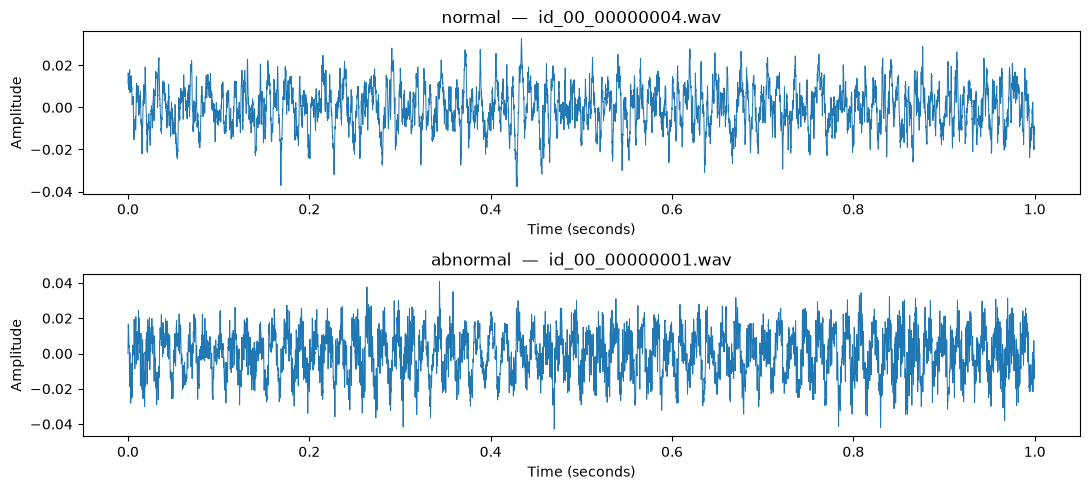

In [5]:
fig,axes=plt.subplots(2,1,figsize=(11,5),sharex=False)
for ax,label in zip(axes,['normal','abnormal']):
    rec=next(x for x in records if x['split']=='train' and x['label']==label)
    waveform=decode_audio(rec['path'])
    ax.plot(np.arange(min(len(waveform),16000))/16000,waveform[:16000],linewidth=.7)
    ax.set(title=f'{label}  —  {Path(rec["path"]).name}',xlabel='Time (seconds)',ylabel='Amplitude')
plt.tight_layout()


## 3. Audio data processing
Decode WAV, average eight channels into mono, resample to **16 kHz**, trim to up to **10 seconds**, compute **20 MFCC means and standard deviations**, plus RMS energy, spectral centroid, bandwidth, roll-off, flatness and zero-crossing rate (mean + standard deviation). These acoustic features come from the **raw audio**, not the old summative CSV. There are 52 learned input descriptors. The scaler fits on training data only.

In [6]:
Xtr,ytr,train_records=features_for([r for r in records if r['split']=='train'])
Xv,yv,val_records=features_for([r for r in records if r['split']=='val'])
Xt,yt,test_records=features_for([r for r in records if r['split']=='test'])
print('train:',Xtr.shape,'validation:',Xv.shape,'test:',Xt.shape)
print('Missing or infinite:',np.count_nonzero(~np.isfinite(Xtr)))
assert Xtr.shape[1]==len(FEATURE_NAMES)==52
assert set(ytr)=={0,1} and set(yv)=={0,1} and set(yt)=={0,1}


train: (420, 52) validation: (90, 52) test: (90, 52)
Missing or infinite: 0


## 4. Exploratory data analysis and THREE feature interpretations
Comparing these features across training labels creates a class-based explanation. Avoid claiming that a high acoustic feature value alone uniquely identifies a physical fault.

rms_mean                   spectral_centroid_mean              \
             mean   median      std                   mean      median   
label                                                                    
abnormal  0.01079  0.01033  0.00149             1192.03011  1142.29324   
normal    0.00968  0.00984  0.00072             1300.06827  1186.35674   

                    zero_crossing_rate_mean                    
                std                    mean   median      std  
label                                                          
abnormal  300.26758                 0.06804  0.06275  0.02831  
normal    378.65432                 0.08355  0.07003  0.04107

RMS compares acoustic energy, centroid compares spectral frequency center, and zero-crossing rate compares waveform sign-change rates.
WRITE ACTUAL NUMERICAL OBSERVATIONS FROM THE PLOTS ABOVE in your presentation: three features, how class means differ, and limitations.


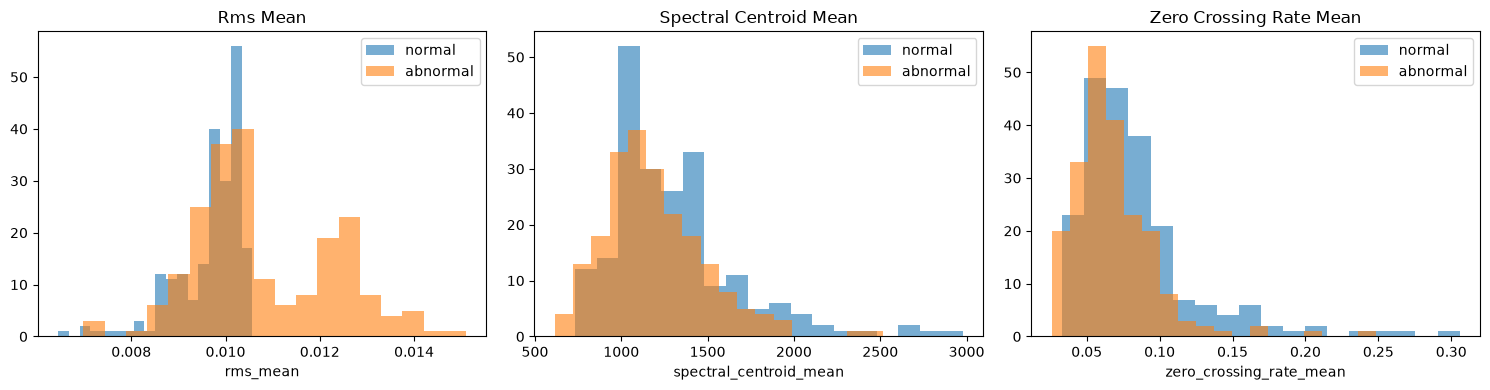

In [7]:
df=pd.DataFrame(Xtr,columns=FEATURE_NAMES)
df['label']=np.where(ytr==1,'abnormal','normal')
features=['rms_mean','spectral_centroid_mean','zero_crossing_rate_mean']
display(df.groupby('label')[features].agg(['mean','median','std']).round(5))
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,f in zip(axs,features):
    for label in ['normal','abnormal']:
        ax.hist(df.loc[df.label==label,f],bins=18,alpha=.6,label=label)
    ax.set(title=f.replace('_',' ').title(),xlabel=f)
    ax.legend()
plt.tight_layout()
print('RMS compares acoustic energy, centroid compares spectral frequency center, and zero-crossing rate compares waveform sign-change rates.')
print('WRITE ACTUAL NUMERICAL OBSERVATIONS FROM THE PLOTS ABOVE in your presentation: three features, how class means differ, and limitations.')


## 5. Baseline and optimized custom MLP training
Optimization: hidden layers (64,32), **Adam** optimizer, **L2 `alpha=0.01` regularization**, standardization, and **validation-loss early stopping with best-weight restoration**. The model is created by this project and saved to `models/current_sense_audio.pkl` for use in production and subsequent retraining.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
baseline=DummyClassifier(strategy='most_frequent').fit(Xtr,ytr)
print('Dummy baseline test accuracy:',round(accuracy_score(yt,baseline.predict(Xt)),4))
print('Dummy baseline test F1:',round(f1_score(yt,baseline.predict(Xt),zero_division=0),4))
# This function performs all train/val/test feature extraction and saves true measured outputs.
experiment=train_initial('data',synthetic_fixture=False)
print('Model saved. No synthetic results have been substituted.')


Dummy baseline test accuracy: 0.5
Dummy baseline test F1: 0.0
Saved models\current_sense_audio.pkl, test accuracy=0.689, F1=0.674; synthetic_fixture=False
Model saved. No synthetic results have been substituted.


## 6. Final held-out model evaluation
At least four true metrics: accuracy, precision, recall, F1, balanced accuracy, ROC AUC and log loss. Here **abnormal** is the positive class. The held-out test split is not used for model selection or retraining decisions.

In [9]:
bundle=load_model()
print('Version:',bundle['version'])
print('Training recordings:',bundle['train_file_count'])
test_metrics=bundle['test_metrics']
display(pd.DataFrame([{'metric':k,'result':v} for k,v in test_metrics.items() if k not in ('confusion_matrix','classification_report')]))
display(pd.DataFrame(test_metrics['classification_report']).T)


Version: audio-v1
Training recordings: 420


,metric,result
0,accuracy,0.688889
1,precision,0.707317
2,recall,0.644444
3,f1,0.674419
4,balanced_accuracy,0.688889
5,loss,0.576879
6,roc_auc,0.745679


,precision,recall,f1-score,support
normal,0.673469,0.733333,0.702128,45.000000
abnormal,0.707317,0.644444,0.674419,45.000000
accuracy,0.688889,0.688889,0.688889,0.688889
macro avg,0.690393,0.688889,0.688273,90.000000
weighted avg,0.690393,0.688889,0.688273,90.000000


## 7. Confusion matrix and validation training history

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
cm=np.asarray(test_metrics['confusion_matrix'])
ConfusionMatrixDisplay(cm,display_labels=['normal','abnormal']).plot()
plt.title('Held-out real MIMII test recordings')
plt.show()
history=pd.DataFrame(bundle['history'])
history.plot(x='epoch',y=['validation_loss','validation_f1'],subplots=True,figsize=(8,6),title='Training progress')
plt.tight_layout()


C:\Users\Administrator\AppData\Local\Temp\ipykernel_31184\1123627350.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 8. Model persistence and test prediction
The following reloads the model from disk (not notebook memory), then predicts one held-out WAV clip. It outputs the source label to check correctness.

In [11]:
one=test_records[0]
pred=predict_audio(one['path'])
print('True class:',one['label'],'Predicted:',pred['label'])
print('Abnormal probability:',round(pred['probability_abnormal'],4))
print('Saved model version:',pred['model_version'])


True class: normal Predicted: normal
Abnormal probability: 0.3098
Saved model version: audio-v1


## 9. Deployment, retraining and production monitoring
Start the API using `uvicorn api:app --host 0.0.0.0 --port 8000` and the UI with `streamlit run app.py`. The `/upload` endpoint stores new labeled WAVs in SQLite and `data/uploads`. The `/retrain` action **updates the existing saved MLP weights** by continuing training on existing training samples plus uploaded labeled samples. `/feedback` accepts later verified labels to compute production quality metrics. The original held-out test recordings are never incorporated during retraining. Docker + Locust results must be measured on a real cloud host; code is in `locustfile.py` and `scripts/run_load_tests.sh`.

## 10. Limitations and citations
**Do not conflate** the original UCI current-signal 11-class score with this acoustic normal/abnormal classifier. Current MIMII splits are stratified by recording, not whole machine or session. Dataset class balance is altered when limiting per-class samples and may not resemble operational fault prevalence. Model probabilities require calibration before safety-critical use.

**Source:** Purohit et al. (2019), MIMII Dataset, Zenodo, DOI: 10.5281/zenodo.3384388, CC BY-SA 4.0. Original CurrentSense summative (Oct 2026): https://github.com/tifarekaseke/CurrentSense-Motor-Fault-Classification.